In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy as sp
%matplotlib inline

Obs Calibration of Campaign 2, of Obs lower

In [2]:
cols = [
    "burst",        # Burst counter
    "ensemble",     # Ensemble counter (1-65536)
    "w",            # Velocity Beam1|X|East (m/s) orginally u renamed to w to reflect vertical velocities
    "u",            # Velocity Beam2|Y|North (m/s) originally v now renamed to u to reflect crossh shore velocities
    "v",            # Velocity Beam3|Z|Up (m/s) orginally w now renamed to v to reflect alongshore velocities
    "amp1",         # Amplitude Beam1 (counts)
    "amp2",         # Amplitude Beam2 (counts)
    "amp3",         # Amplitude Beam3 (counts)
    "snr1",         # SNR Beam1 (dB)
    "snr2",         # SNR Beam2 (dB)
    "snr3",         # SNR Beam3 (dB)
    "corr1",        # Correlation Beam1 (%)
    "corr2",        # Correlation Beam2 (%)
    "corr3",        # Correlation Beam3 (%)
    "pressure",     # Pressure (dbar)
    "analog1",      # Analog input 1
    "analog2",      # Analog input 2
    "checksum",     # Checksum (1 = failed)
]

pd_CalTest = pd.read_csv("ObsCalibrationCampaign2.dat", sep=r"\s+", header=None, names=cols)


In [3]:
display(pd_CalTest)
pd_CalTest = pd_CalTest['analog1']

,burst,ensemble,w,u,v,amp1,amp2,amp3,snr1,snr2,snr3,corr1,corr2,corr3,pressure,analog1,analog2,checksum
0,1,1,0.178,0.187,-0.396,56,55,52,-1.3,0.0,-0.4,11,9,16,0.000,929,0,0
1,1,2,0.110,-0.345,0.164,60,53,53,0.4,-0.9,0.0,13,12,33,0.000,933,0,0
2,1,3,-0.443,-1.273,-0.261,60,58,51,0.4,1.3,-0.9,13,21,17,0.000,935,0,0
3,1,4,-1.247,0.129,-0.189,57,56,57,-0.9,0.4,1.7,11,33,10,0.000,940,0,0
4,1,5,-2.160,-0.956,-0.152,57,56,54,-0.9,0.4,0.4,10,4,27,0.000,941,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105696,1,40161,1.173,0.739,-0.137,56,55,55,-1.3,0.0,0.9,19,8,17,0.011,41450,0,0
105697,1,40162,2.594,-0.930,0.200,57,53,54,-0.9,-0.9,0.4,1,7,17,0.012,41360,0,0
105698,1,40163,-1.042,-0.138,-0.098,57,53,54,-0.9,-0.9,0.4,16,15,23,0.012,41368,0,0
105699,1,40164,0.744,0.906,0.113,56,56,50,-1.3,0.4,-1.3,33,18,17,0.009,41451,0,0


- 24 Calibration test steps were analysed (25 including the background signal of the test setup)

<Axes: title={'center': 'Calibration Test'}, xlabel='Index', ylabel='Obs output, Voltage (V)'>

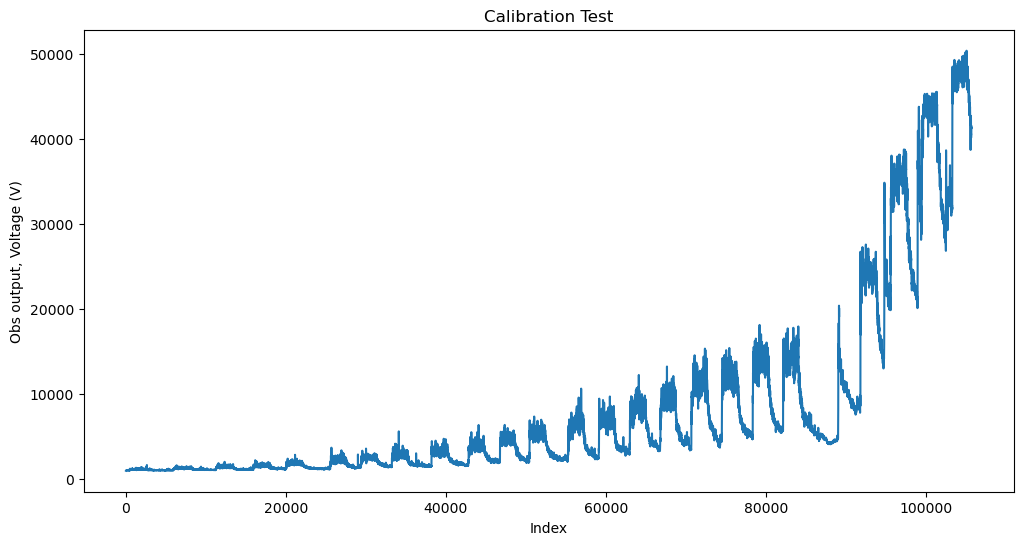

In [4]:
# display(pd_CalTest)
pd_CalTest.plot(figsize=(12, 6), title='Calibration Test', xlabel='Index', ylabel='Obs output, Voltage (V)')

In [5]:
levels = ['14:52', '14:58', '15:04', '15:09', '15:13', '15:19', '15:23', '15:27', '15:32', '15:37', 
          '15:41', '15:45', '15:50', '15:54', '15:58', '16:02', '16:06', '16:10', '16:14', '16:18']
levels01 = [510, 6200, 11400, 16100, 20200, 25700, 29500, 33400, 38300, 43300, 47100, 50500, 55500, 59300, 63500, 67300, 71000, 74800, 78400, 82300]
values01 = [0.0375, 0.0775, 0.1275, 0.1975, 0.3025, 0.4425, 0.575, 0.7375, 0.9325, 1.18, 1.4225, 1.67, 1.915, 2.3175, 2.705, 3.14, 3.525, 3.915, 4.325, 4.605] #Concentrations in g/L

levels2 = ['16:28', '16:32', '16:36', '16:40']
levels02 = [92000, 96200, 99700, 103500]
values02 = [6.0, 8.0675, 9.9325, 11.1425]

sampling_frequency = 16 #Hz

In [6]:
display(pd_CalTest)

0           929
1           933
2           935
3           940
4           941
          ...  
105696    41450
105697    41360
105698    41368
105699    41451
105700    41515
Name: analog1, Length: 105701, dtype: int64

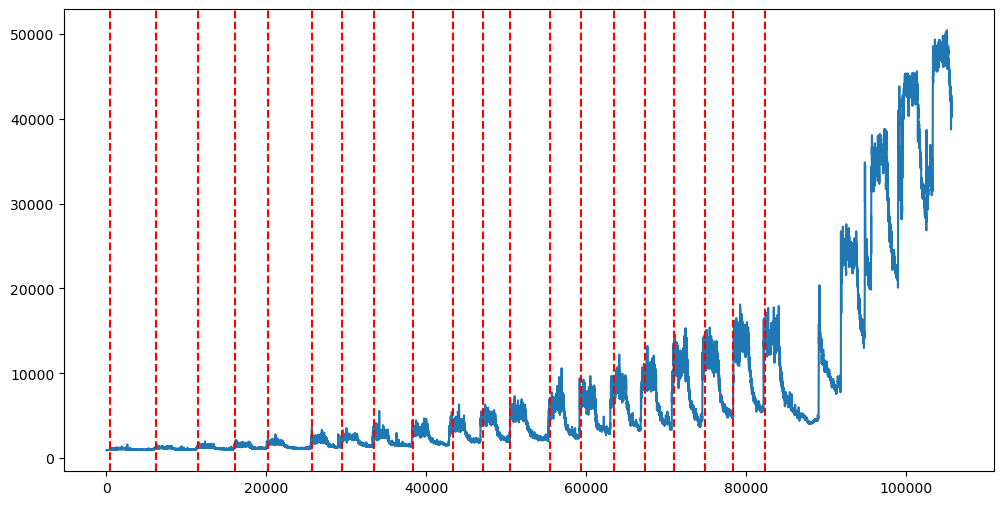

In [7]:
fig, ax = plt.subplots(figsize=(12, 6))

plt.plot(pd_CalTest)
for i in range(len(levels01)):
    plt.axvline(x=levels01[i], color='r', linestyle='--', label=levels[i])

In [8]:
def average(data, samp, levels):
    averaged_levels = []
    background_signal = 950 
    jump = int(samp * 60)  # Convert minutes to number of samples
    for i in range(len(levels)):
        start_index = levels[i]
        end_index = levels[i] + jump

        segment = data[start_index:end_index]
        averaged_value = float(np.mean(segment)) - float(background_signal)  # Average minus standard deviation

        averaged_levels.append(averaged_value)

    return averaged_levels

In [9]:
results01 = average(pd_CalTest, sampling_frequency, levels01)
results02 = average(pd_CalTest, sampling_frequency, levels02)
print(results01)
print(results02)

[124.22604166666656, 286.47708333333344, 423.8260416666667, 576.9802083333334, 846.9833333333333, 1157.5229166666668, 1484.0281249999998, 1776.3041666666668, 2193.8083333333334, 2929.928125, 3789.2093750000004, 4400.140625, 5263.298958333334, 5998.320833333333, 7609.067708333334, 8582.640625, 10003.298958333333, 11285.522916666667, 12456.552083333334, 13062.814583333333]
[23368.54375, 34668.74791666667, 42636.04375, 46655.707291666666]


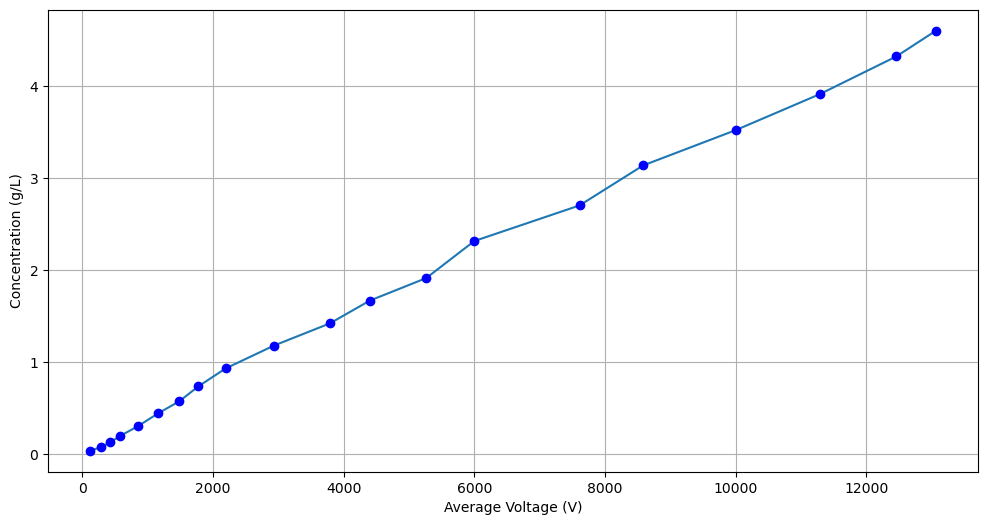

In [10]:
plt.figure(figsize=(12, 6))

plt.plot(results01, values01, label='Calibration Data')
plt.plot(results01, values01, 'bo', label='Calibration Data')
plt.xlabel('Average Voltage (V)')
plt.ylabel('Concentration (g/L)')
plt.grid()

In [11]:
def lin1(x, a, b):
    return a * x + b


vara1, *rest = sp.optimize.curve_fit(lin1, results01, values01)
print(vara1)
vara2, *rest = sp.optimize.curve_fit(lin1, results02, values02)
print(vara2)

results03 = np.append(results01, results02)
values03 = np.append(values01, values02)
#Total of all
vara3, *rest = sp.optimize.curve_fit(lin1, results03, values03)
print(vara3)

[0.00034892 0.06320014]
[2.17840701e-04 7.62059516e-01]
[2.31403543e-04 5.57918067e-01]


In [12]:
results01 = np.asarray(results01, dtype=np.float64)
results02 = np.asarray(results02, dtype=np.float64)

x = np.linspace(0, 60000, 100)
y1 = vara1[0] * x + vara1[1]

y2 = vara2[0] * x + vara2[1]

y3 = vara3[0] * x + vara3[1]


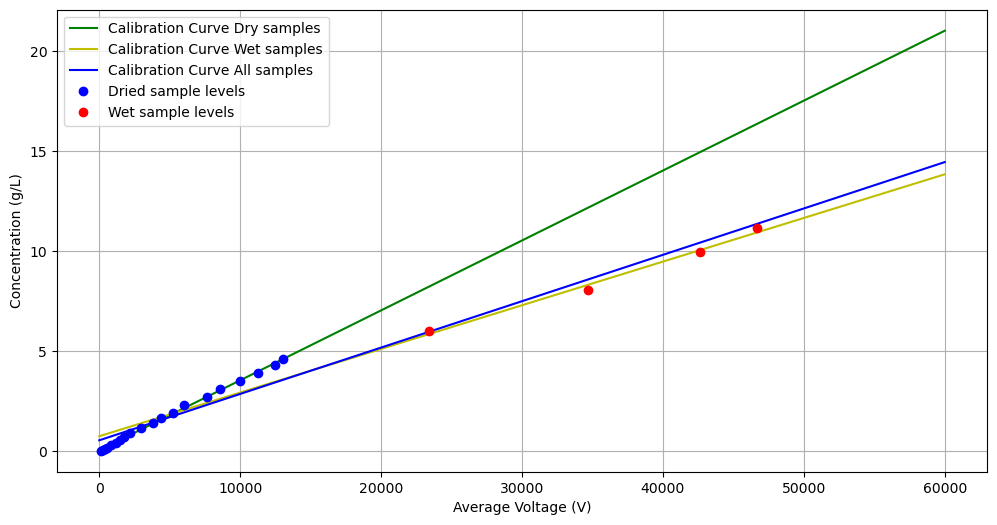

In [13]:
plt.figure(figsize=(12, 6))

plt.plot(x, y1, label='Calibration Curve Dry samples', color='g')
plt.plot(x, y2, label='Calibration Curve Wet samples', color='y')
plt.plot(x, y3, label='Calibration Curve All samples', color='b')

plt.plot(results01, values01, 'bo', label='Dried sample levels')

plt.plot(results02, values02, 'ro', label='Wet sample levels')
# plt.ylim(-1,10)
# plt.xlim(0, 20000)
plt.xlabel('Average Voltage (V)')
plt.ylabel('Concentration (g/L)')
plt.legend()
plt.grid()

Fit accuracy

In [14]:
#Juts the dried samples accuracy:
x = np.asarray(results01, dtype=float)
observed = np.asarray(values01, dtype=float)

fitted = vara1[0] * x + vara1[1]
residuals = observed - fitted

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(observed, fitted)
rmse = np.sqrt(mean_squared_error(observed, fitted))
r2 = r2_score(observed, fitted)
bias = np.mean(residuals)

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")
print(f"Bias: {bias:.4f}")

MAE:  0.0620
RMSE: 0.0726
R²:   0.9976
Bias: 0.0000


In [15]:
#Just the wet samples accuracy:
x = np.asarray(results02, dtype=float)
observed = np.asarray(values02, dtype=float)

fitted = vara2[0] * x + vara2[1]
residuals = observed - fitted

mae = mean_absolute_error(observed, fitted)
rmse = np.sqrt(mean_squared_error(observed, fitted))
r2 = r2_score(observed, fitted)
bias = np.mean(residuals)

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")  
print(f"R²:   {r2:.4f}")
print(f"Bias: {bias:.4f}")

MAE:  0.1821
RMSE: 0.1894
R²:   0.9905
Bias: 0.0000


In [16]:
#All tests together test:
x = np.asarray(results03, dtype=float)
observed = np.asarray(values03, dtype=float)

fitted = vara3[0] * x + vara3[1]
residuals = observed - fitted

mae = mean_absolute_error(observed, fitted)
rmse = np.sqrt(mean_squared_error(observed, fitted))
r2 = r2_score(observed, fitted)
bias = np.mean(residuals)

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")  
print(f"R²:   {r2:.4f}")
print(f"Bias: {bias:.4f}")

MAE:  0.4107
RMSE: 0.4869
R²:   0.9748
Bias: -0.0000


**Testing an exponential fit**: Might be a more appropriate fit for the OBS visuals

In [17]:
def expon(x, a, b):
    return (a * x)**0.5 + b

vara31, *rest = sp.optimize.curve_fit(expon, results03, values03)
print(vara31)


x = np.linspace(1, 60000, 100)
y4 = (vara31[0] * x)**0.5 + vara31[1]

[ 0.00276192 -1.42420437]


/var/folders/3q/ddmvnbcj1f790651pr18mj9r0000gn/T/ipykernel_71020/3939786660.py:2: RuntimeWarning: invalid value encountered in sqrt
  return (a * x)**0.5 + b


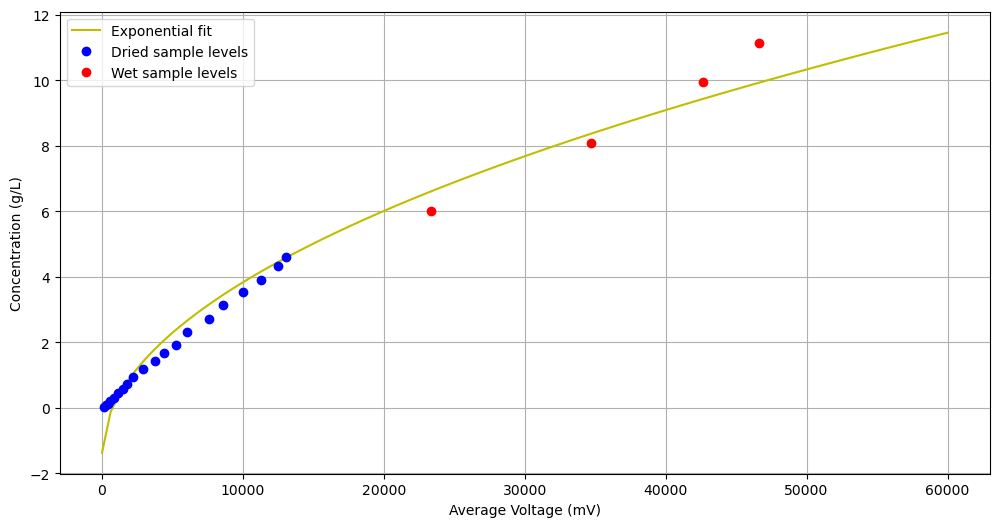

In [18]:
plt.figure(figsize=(12, 6))

# plt.plot(x, y1, label='Calibration Curve Dry samples', color='g')

plt.plot(x, y4, label='Exponential fit', color='y')

plt.plot(results01, values01, 'bo', label='Dried sample levels')

plt.plot(results02, values02, 'ro', label='Wet sample levels')
# plt.ylim(-1,10)
# plt.xlim(0, 20000)
plt.xlabel('Average Voltage (mV)')
plt.ylabel('Concentration (g/L)')
plt.legend()
plt.grid()

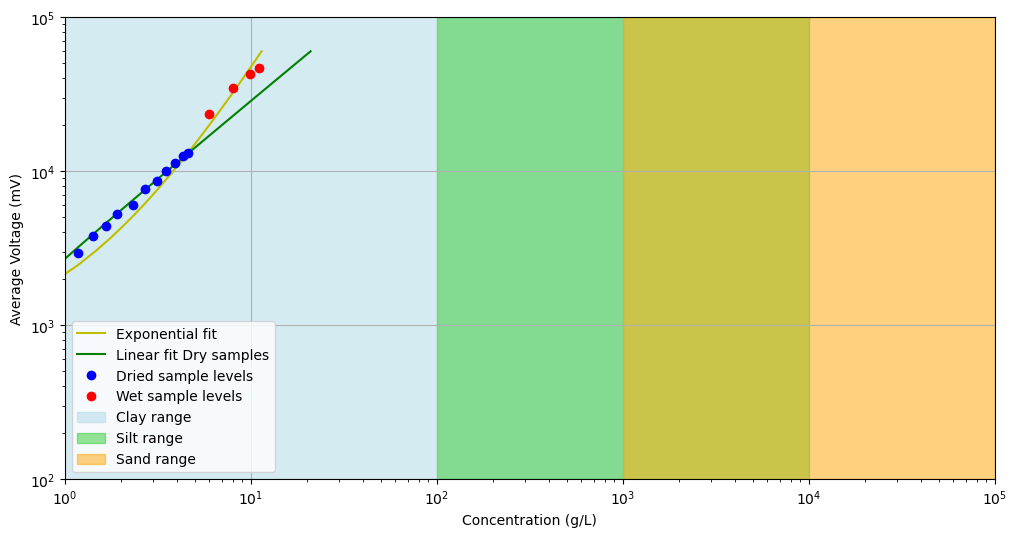

In [19]:
plt.figure(figsize=(12, 6))

# plt.plot(x, y1, label='Calibration Curve Dry samples', color='g')

plt.plot(y4, x, label='Exponential fit', color='y')
plt.plot(y1, x, label='Linear fit Dry samples', color='g')

plt.plot(values01, results01, 'bo', label='Dried sample levels')
plt.plot(values02, results02, 'ro', label='Wet sample levels')

plt.xscale("log")
plt.yscale("log")


plt.axvspan(0, 10e2, color='lightblue', alpha=0.5, label='Clay range')
plt.axvspan(10e1, 10e3, color='limegreen', alpha=0.5, label='Silt range')
plt.axvspan(10e2, 10e4, color='orange', alpha=0.5, label='Sand range')

plt.xlim(1, 10e4)
plt.ylim(100, 10e4)

plt.ylabel('Average Voltage (mV)')
plt.xlabel('Concentration (g/L)')
plt.legend()
plt.grid()